# primus-paleo — 01: the basics

**What the package answers:** *how many nuclear-recoil tracks, and of what length, has a mineral accumulated from
cosmic rays (and from its own radioactivity), given where it sat and what flux it saw?*

The four steps of the seminar's *Interrogating a mineral* slide, and the calls that do them:

| step | physics | in `primus_paleo` |
|---|---|---|
| 1. flux at the surface, and when | MCEq templates | `pp.FluxHistory` |
| 2. rock above the sample over time | overburden history | `overburden_history=` of `pp.Paleodetector` |
| 3. what the secondaries do in the target | Geant4 runs (mineral + StdRock) | read by `pp.Paleodetector` |
| 4. recoil → track length, integrated in time | Geant4 range tables | `det.integrate_*` |

**Running example:** an olivine sample, 100 kyr old, under 3 m.w.e. (about 1 m of rock) the whole time.
Olivine is the standard target of the dark-matter / neutrino paleo-detector studies and the mineral of our
Chaîne des Puys xenoliths.

⏱ marks the slow cells: each reads the Geant4 outputs of the mineral (~1 min per species on a laptop), ~30 min in
total. Each slow cell saves its result in `demo_cache/` and loads it on later runs; set `RERUN = True` in the first
cell to recompute.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import primus_paleo as pp

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False, "font.size": 11})
Path("figures").mkdir(exist_ok=True)          # slide-ready PNGs are saved here

RERUN = True                              # True: recompute every slow cell and overwrite its file
CACHE = Path("demo_cache"); CACHE.mkdir(exist_ok=True)

print("primus_paleo", pp.__version__)
pp.describe()

primus_paleo 0.1.0
data root           /home/claudio/primus-paleo/Data  (ok)
mineral library     /home/claudio/primus-paleo/Data/mineral_library.yaml  (ok)
flux templates      /home/claudio/primus-paleo/Data/flux_data  (ok)
Geant4 outputs      /home/claudio/primus-paleo/Data/Geant4_data  (ok)
Geant4 application  /home/claudio/primus-paleo/geant4/build/Run  (ok)


## 0. Where things are, and the mineral library

The data root (`Data/`) is found automatically from an editable install; `pp.set_data_path(...)` or the
`PRIMUS_DATA` environment variable point elsewhere. Minerals are defined in `Data/mineral_library.yaml`:
composition, density, uranium concentration, (α,n) coefficient.

In [2]:
print("minerals in the library:", list(pp.load_mineral_library()))
pp.mineral_config("Olivine")

minerals in the library: ['Halite', 'Olivine', 'Quartz', 'Spinel', 'Apatite', 'Orthopyroxene', 'Clinopyroxene', 'Diamond', 'Calcite', 'Obsidian']


{'name': 'Olivine',
 'nuclei': ['Mg', 'Fe', 'Si', 'O'],
 'stoich': [2.57, 0.29, 1.43, 5.71],
 'uranium_concentration_g_g': 1e-09,
 'density_g_cm3': 3.3,
 'an_coeff_n_nalpha': 0.1}

A mineral can be **simulated** only if it has Geant4 runs in `Data/Geant4_data/<mineral>/` (here: Halite, Olivine,
Diamond; Obsidian has range tables only, for fission tracks). Adding one is in notebook 03.

## 1. The flux at the surface — `FluxHistory`

`pp.FluxHistory()` is the present-day baseline: MCEq solution at sea level, 5 GV geomagnetic cutoff, integrated over
zenith angle (flux through a horizontal surface, cm⁻² s⁻¹ GeV⁻¹). Saved templates load without MCEq.
Below a few GeV the nucleons are spliced to measured shapes (Gordon et al. neutrons), and the neutrinos are
extended to the ~40 MeV peak.

`flux.flux(species, energy_gev, t_kyr)`; the flux clock runs **0 = present, negative = past** (kyr).

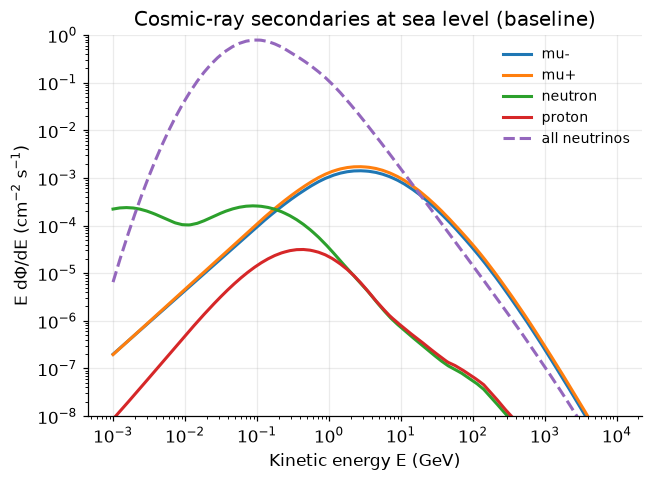

mu-      integrated flux above 1 MeV: 4.63e-03 cm^-2 s^-1
mu+      integrated flux above 1 MeV: 5.58e-03 cm^-2 s^-1
neutron  integrated flux above 1 MeV: 1.20e-03 cm^-2 s^-1
proton   integrated flux above 1 MeV: 8.86e-05 cm^-2 s^-1


In [3]:
flux = pp.FluxHistory()
E = np.logspace(-3, 4, 300)          # GeV

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for s in ["mu-", "mu+", "neutron", "proton"]:
    ax.loglog(E, E * flux.flux(s, E, 0.0), lw=2, label=s)
nu_all = sum(flux.flux(s, E, 0.0) for s in pp.NEUTRINO_SPECIES)
ax.loglog(E, E * nu_all, lw=2, ls="--", label="all neutrinos")
ax.set(xlabel="Kinetic energy E (GeV)", ylabel=r"E dΦ/dE (cm$^{-2}$ s$^{-1}$)", ylim=(1e-8, 1),
       title="Cosmic-ray secondaries at sea level (baseline)")
ax.legend(fontsize=9)
fig.savefig("figures/01_ground_level_flux.png", dpi=200, bbox_inches="tight")
plt.show()

for s in ["mu-", "mu+", "neutron", "proton"]:
    print(f"{s:8s} integrated flux above 1 MeV: {np.trapezoid(flux.flux(s, E, 0.0), E):.2e} cm^-2 s^-1")

## 2. The detector — `Paleodetector`

`pp.Paleodetector(mineral, total_age_kyr, overburden_history, flux_history)`. On creation it:
* reads the list of Geant4 runs of the mineral (which species, which energies),
* builds the **depth tables** from the StdRock runs: where muons stop and where hadrons interact in a generic
  crust — this is how the overburden attenuates each species,
* builds an adaptive **time grid** on the overburden and flux histories.

The overburden is in **m.w.e.** (metres of water equivalent = 100 g/cm²); a number means constant.
The detector has its own clock, **local time**: 0 = when the sample starts recording, `total_age_kyr` = today.

In [4]:
AGE_KYR = 100.0
DEPTH_MWE = 3.0

det = pp.Paleodetector("Olivine", total_age_kyr=AGE_KYR, overburden_history=DEPTH_MWE)
print("\ncomputable cosmic-ray species:", det.available_species())

Time grid: 100 nodes over 0-100 kyr (100 uniform and breakpoint nodes, 0 added where the overburden or flux change; 0 flux events, 0 excursions)
Created paleo-detector Olivine, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 163 steps
  neutron    energy from 0.001 to 171.9 GeV in 90 steps
  proton     energy from 0.001 to 58.17 GeV in 82 steps
  nu_mu      energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_mu energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  nu_e       energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_e  energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock r

The warnings about missing files are the run grid telling the truth: the muon runs above ~130 GeV are sparse,
and they stop at ~170 GeV in olivine (~300 GeV in StdRock). **With the shipped runs the muon spectrum is
complete only down to a few hundred m.w.e.** — deeper samples need higher-energy muon runs.

## 3. Cosmic-ray tracks — `integrate_all_particles`

One call computes every species in parallel and integrates over the exposure: tracks **per mg**, in bins of track
length (nm). The species:

* `mu-`, `mu+`, `neutron`, `proton`: the atmospheric particles reaching the sample through the overburden
  (`mu-` includes nuclear capture at rest);
* `secondary_neutron`, `secondary_proton`: neutrons and protons **made in the rock above the sample** by all of the
  above, all generations of the n+p cascade included.

The split between *atmospheric* and *made in the rock* is the bookkeeping of one cascade (a particle is
"atmospheric" until its first interaction, its products are secondaries): their **sum** is the physical quantity.

Light ions (p, d, t, α) leave sparse damage, not an etchable track, and are left out by default
(`nucleus='total_no_light_ions'`; `nucleus='total'` keeps them).

We use the package's fine logarithmic length grid `pp.TRACK_LENGTH_BINS_NM` (32 nm – 316 µm) to see short tracks;
without `x_bins` the default is 100 nm linear bins up to 50 µm.

In [7]:
cache = CACHE / "01_cosmic_rays.npz"

bins = pp.TRACK_LENGTH_BINS_NM

if RERUN or not cache.exists():
    x_bins, cr = det.integrate_all_particles(x_bins=bins)
    np.savez(cache, **cr)
else:
    x_bins, cr = bins, dict(np.load(cache))

for s, counts in cr.items():
    print(f"{s:18s} {counts.sum():10.3g} tracks/mg")

 20%|██        | 1/5 [01:52<07:29, 112.49s/it]

 60%|██████    | 3/5 [02:12<01:13, 36.53s/it] 

100%|██████████| 5/5 [06:31<00:00, 78.37s/it]

mu-                  6.84e+03 tracks/mg
mu+                   2.6e+03 tracks/mg
neutron                   237 tracks/mg
proton                   4.89 tracks/mg
secondary_neutron    2.31e+05 tracks/mg
secondary_proton          288 tracks/mg
total                2.41e+05 tracks/mg


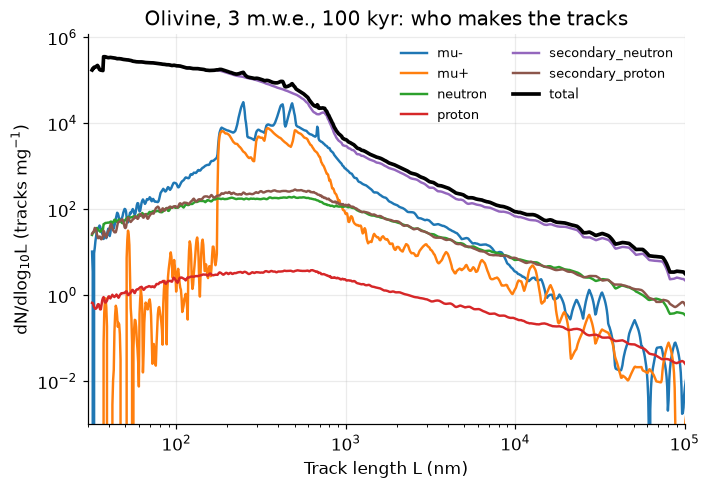

In [8]:
x_mid = np.sqrt(x_bins[1:] * x_bins[:-1])
dlog = np.diff(np.log10(x_bins))               # counts / dlog = dN/dlog10(L)

fig, ax = plt.subplots(figsize=(7, 4.6))
for s in det.available_species():
    ax.loglog(x_mid, cr[s] / dlog, lw=1.6, label=s)
ax.loglog(x_mid, cr["total"] / dlog, color="k", lw=2.4, label="total")
ax.set(xlabel="Track length L (nm)", ylabel=r"dN/dlog$_{10}$L (tracks mg$^{-1}$)", xlim=(200, 1e5), ylim=(1e-3, None),
       title=f"Olivine, {DEPTH_MWE:g} m.w.e., {AGE_KYR:g} kyr: who makes the tracks")
ax.legend(fontsize=8.5, ncol=2)
fig.savefig("figures/02_track_spectrum_by_species.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. The mineral's own background: fission and radiogenic neutrons

Both scale with the uranium concentration (from the library: 1 ppb for olivine).
* **Fission tracks**: the two fragments of ²³⁸U spontaneous fission — a narrow peak (~7–8 µm in olivine).
* **Radiogenic neutrons**: from spontaneous fission and (α,n), propagated with the same Geant4 neutron runs as the
  cosmic neutrons.

These do not depend on the overburden — only on age and U content.

In [9]:
cache = CACHE / "01_backgrounds.npz"
if RERUN or not cache.exists():
    _, fission = det.integrate_fission_spectrum(x_bins=x_bins)
    _, radiogenic = det.integrate_background_neutron_spectrum(x_bins=x_bins)
    np.savez(cache, fission=fission, radiogenic=radiogenic)
else:
    saved = np.load(cache)
    fission, radiogenic = saved["fission"], saved["radiogenic"]

U = det.config["uranium_concentration_g_g"]
print(f"U = {U:g} g/g:  fission {fission.sum():.3g}, radiogenic n {radiogenic.sum():.3g} tracks/mg "
      f"(cosmic rays: {cr['total'].sum():.3g})")

Calculating spontaneous fission background...
Processing background neutron tracks from fission_n
Processing background neutron tracks from alpha_n
U = 1e-09 g/g:  fission 0.0212, radiogenic n 2.35 tracks/mg (cosmic rays: 2.41e+05)


## 5. Atmospheric neutrinos — `integrate_atmospheric_neutrinos`

Neutrinos are not attenuated by any overburden and arrive from the whole sphere (up-going through the Earth
included), so this rate depends only on the flux history. Two parts:
* the neutrinos' **own** interactions in the sample (CEνNS and the rest),
* the muons, neutrons and protons they **make in the surrounding rock** (`nu_secondary_*`), in equilibrium,
  all generations included.

The Geant4 neutrino runs are biased (cross-sections multiplied by a large factor); the bias is read from
`geometry.json` and divided out.

In [10]:
cache = CACHE / "01_neutrinos.npz"
if RERUN or not cache.exists():
    _, nu = det.integrate_atmospheric_neutrinos(x_bins=x_bins)
    np.savez(cache, **nu)
else:
    nu = dict(np.load(cache))

for s, counts in nu.items():
    print(f"{s:22s} {counts.sum():10.3g} tracks/mg")

Neutrino secondaries made in the mineral (no StdRock runs for ['nu_mu', 'anti_nu_mu', 'nu_e', 'anti_nu_e']).
Neutrinos nu_mu (Olivine runs): 75 runs, bias 1e+08, biased interactions per primary up to 0.0201
Neutrinos anti_nu_mu (Olivine runs): 75 runs, bias 1e+08, biased interactions per primary up to 0.0101
Neutrinos nu_e (Olivine runs): 75 runs, bias 1e+08, biased interactions per primary up to 0.0225
Neutrinos anti_nu_e (Olivine runs): 75 runs, bias 1e+08, biased interactions per primary up to 0.0152
nu_mu                    1.39e-09 tracks/mg
anti_nu_mu               8.57e-10 tracks/mg
nu_e                     1.66e-09 tracks/mg
anti_nu_e                7.15e-10 tracks/mg
nu_secondary_mu-         2.32e-09 tracks/mg
nu_secondary_mu+         1.93e-10 tracks/mg
nu_secondary_neutron     7.42e-07 tracks/mg
nu_secondary_proton      1.34e-09 tracks/mg
total                     7.5e-07 tracks/mg


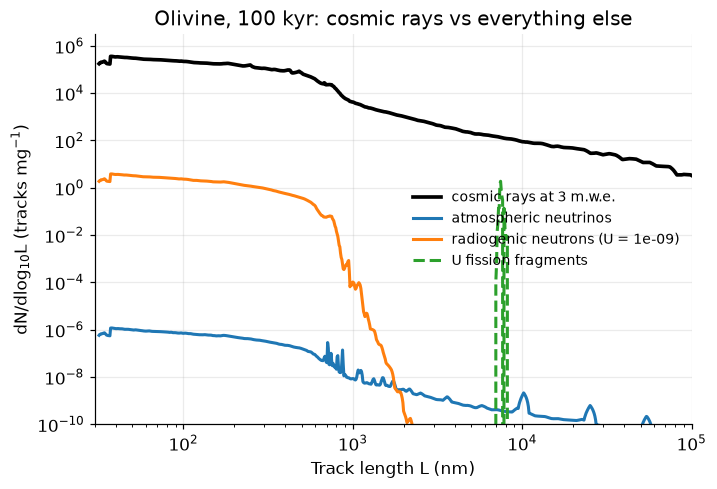

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.loglog(x_mid, cr["total"] / dlog, color="k", lw=2.4, label=f"cosmic rays at {DEPTH_MWE:g} m.w.e.")
ax.loglog(x_mid, nu["total"] / dlog, lw=2, label="atmospheric neutrinos")
ax.loglog(x_mid, radiogenic / dlog, lw=2, label=f"radiogenic neutrons (U = {U:g})")
ax.loglog(x_mid, fission / dlog, lw=2, ls="--", label="U fission fragments")
ax.set(xlabel="Track length L (nm)", ylabel=r"dN/dlog$_{10}$L (tracks mg$^{-1}$)", xlim=(30, 1e5), ylim=(1e-10, None),
       title=f"Olivine, {AGE_KYR:g} kyr: cosmic rays vs everything else")
ax.legend(fontsize=9)
fig.savefig("figures/03_signal_vs_backgrounds.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. How the rate falls with depth

The question for any rare-event sample: *at which depth do cosmic rays stop mattering?*

`integrate_*` integrates a rate over time; `det.calculate_particle_signal_spectrum(t_kyr_array, ...)` returns the rate
itself (tracks mg⁻¹ kyr⁻¹ nm⁻¹) at given local times. The cost is reading the Geant4 files, not the number of times,
so we ask for many times at once. **Trick:** a detector whose overburden grows by 1 m.w.e. per kyr turns local time
into depth, and one call per species gives the whole depth profile.

We also check how many tracks fall in 30 nm – 1 µm, the window where WIMP and CEνNS recoils live.

In [12]:
depths = np.logspace(-1, 3, 33)                 # m.w.e.
ramp = pp.Paleodetector("Olivine", total_age_kyr=depths[-1] * 1.01,
                        overburden_history={"initial_depth": 0.0, "rate_continuous": [1.0],
                                            "density_continuous_g_cm3": [1.0]})   # depth [m.w.e.] = local time [kyr]

cache = CACHE / "01_rate_vs_depth.npz"
if RERUN or not cache.exists():
    rate = {s: ramp.calculate_particle_signal_spectrum(depths, x_bins=x_bins, species=s)
            for s in ramp.available_species()}
    np.savez(cache, **rate)
else:
    rate = dict(np.load(cache))

Interpolating overburden history...
Time grid: 251 nodes over 0-1010 kyr (100 uniform and breakpoint nodes, 151 added where the overburden or flux change; 0 flux events, 0 excursions)
Created paleo-detector Olivine, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 163 steps
  neutron    energy from 0.001 to 171.9 GeV in 90 steps
  proton     energy from 0.001 to 58.17 GeV in 82 steps
  nu_mu      energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_mu energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  nu_e       energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_e  energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; second

fraction of cosmic-ray tracks in 30 nm - 1 um: [0.994 0.994 0.998 0.995 0.996] at [1.e-01 1.e+00 1.e+01 1.e+02 1.e+03] m.w.e.


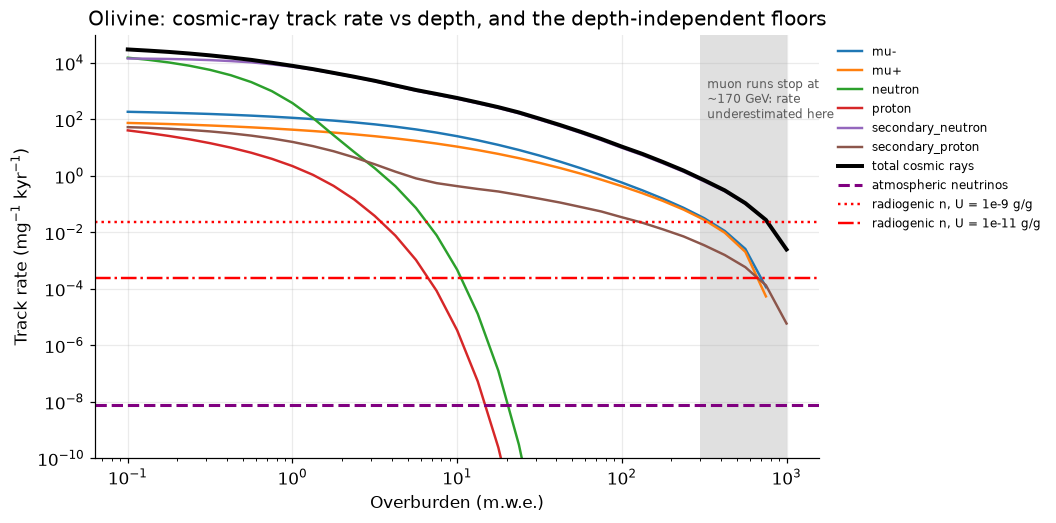

In [13]:
width = np.diff(x_bins)
rate_vs_depth = {s: (r * width).sum(axis=1) for s, r in rate.items()}          # tracks/mg/kyr
total = sum(rate_vs_depth.values())
in_window = (x_mid >= 30) & (x_mid <= 1000)
total_window = sum((r * width)[:, in_window].sum(axis=1) for r in rate.values())
print("fraction of cosmic-ray tracks in 30 nm - 1 um:", np.round(total_window[::8] / total[::8], 3),
      "at", depths[::8], "m.w.e.")

fig, ax = plt.subplots(figsize=(8.5, 5))
for s, y in rate_vs_depth.items():
    ax.loglog(depths, np.where(y > 0, y, np.nan), lw=1.6, label=s)
ax.loglog(depths, total, color="k", lw=2.6, label="total cosmic rays")
ax.axhline(nu["total"].sum() / AGE_KYR, color="purple", lw=2, ls="--", label="atmospheric neutrinos")
ax.axhline(radiogenic.sum() / AGE_KYR, color="red", lw=1.6, ls=":", label="radiogenic n, U = 1e-9 g/g")
ax.axhline(radiogenic.sum() / AGE_KYR * 1e-11 / U, color="red", lw=1.6, ls="-.", label="radiogenic n, U = 1e-11 g/g")
ax.axvspan(300, depths[-1], color="0.88", lw=0, zorder=0)
ax.text(330, 3e3, "muon runs stop at\n~170 GeV: rate\nunderestimated here", fontsize=8, color="0.35", va="top")
ax.set(xlabel="Overburden (m.w.e.)", ylabel=r"Track rate (mg$^{-1}$ kyr$^{-1}$)", ylim=(1e-10, 1e5),
       title="Olivine: cosmic-ray track rate vs depth, and the depth-independent floors")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.savefig("figures/04_rate_vs_depth.png", dpi=200, bbox_inches="tight")
plt.show()

Reading the plot:
* essentially **all** cosmic-ray tracks (>99%) are in the 30 nm – 1 µm window, at every depth: exactly where
  WIMP and CEνNS recoils are searched for;
* atmospheric neutrons matter only in the first metre; from there down, ~90% of the tracks come from neutrons
  **made in the rock** (by atmospheric hadrons near the surface, by muons deeper), and the muons' own interactions
  and captures are 2–9%;
* the rate falls by ~5–6 orders of magnitude from the surface to ~500 m.w.e.; with 1 ppb of uranium the
  radiogenic neutrons take over only around 500–1000 m.w.e., with 0.01 ppb deeper still — **beyond what the shipped
  muon runs cover** (shaded). Deep, low-U samples need muon runs up to tens of TeV;
* the atmospheric-neutrino floor sits far below all of these in this calculation.

## 7. From tracks per mg to what a microscope sees — `slice_spectrum_etch`

A microscope sees only the tracks cut by the polished, etched surface, and as **etch-pit openings**, not as latent
lengths. `pp.slice_spectrum_etch` is the Monte Carlo of that: tracks are placed isotropically in the volume, the
surface is etched (Huygens construction, critical angle included), and pits narrower than the optical resolution
(`min_width_nm`) are dropped. `etch_type='HF'` (wet, isotropic) or `'plasma'` (dry, directional, the PRImuS
halite recipe).

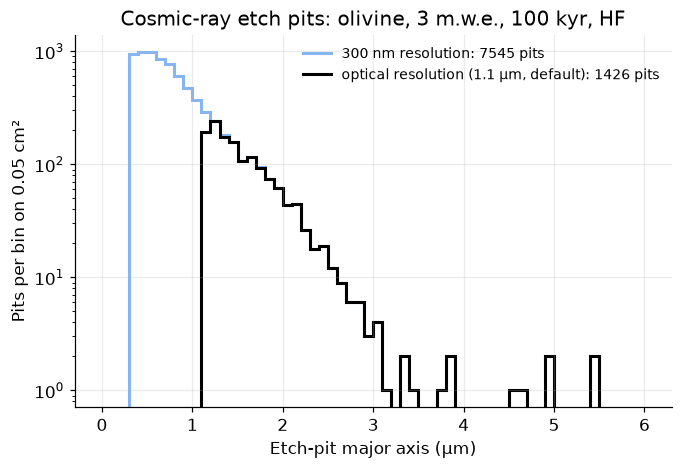

latent tracks longer than 1.1 um: 0.30% of the total


In [14]:
AREA_CM2 = 0.05
pit_bins = np.linspace(0, 6_000, 61)           # nm
fig, ax = plt.subplots(figsize=(7, 4.4))
for min_width, color, label in [(300.0, "#86b6ef", "300 nm resolution"),
                                (1125.0, "k", "optical resolution (1.1 µm, default)")]:
    pits = pp.slice_spectrum_etch(cr["total"], sample_area_cm2=AREA_CM2,
                                  sample_density_g_cm3=det.config["density_g_cm3"], x_bins=x_bins,
                                  out_bins=pit_bins, etch_type="HF", min_width_nm=min_width,
                                  rng=np.random.default_rng(1))
    ax.stairs(pits, pit_bins / 1e3, color=color, lw=2, label=f"{label}: {int(pits.sum())} pits")
ax.set(yscale="log", xlabel="Etch-pit major axis (µm)", ylabel=f"Pits per bin on {AREA_CM2:g} cm²",
       title=f"Cosmic-ray etch pits: olivine, {DEPTH_MWE:g} m.w.e., {AGE_KYR:g} kyr, HF")
ax.legend(fontsize=9)
fig.savefig("figures/05_etched_pits.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"latent tracks longer than 1.1 um: {cr['total'][x_mid > 1125].sum() / cr['total'].sum():.2%} of the total")